# Data Acquisition and Time-Series Synchronization

## Component 4: Multi-Sensor Machine Learning-Based Road Roughness Assessment and Cross-Vehicle-Driver Generalization

This notebook loads the raw PVS datasets, inspects the sensor streams, timestamps, sampling rates and labels, and builds one synchronized file per trip. The synchronized files are the input of Notebooks 02–09.

| Input (per trip, `MyDrive/PVS{n}/`) | Content |
|---|---|
| `dataset_gps_mpu_left.csv` | left-side IMUs (dashboard, above suspension, below suspension) + GPS |
| `dataset_gps_mpu_right.csv` | right-side IMUs + the same GPS |
| `dataset_labels.csv` | per-sample labels: road condition (left/right), surface type, speed bumps |

| Output | Content |
|---|---|
| `MyDrive/PVS{n}/Synced_Data/PVS{n}_synchronized.csv` | 60 columns: timestamp, 27 left + 27 right sensor channels, GPS (4), `road_condition` |

**Reproducibility mode.** With `OVERWRITE = False` (default) the notebook rebuilds every trip and **compares** it with the synchronized file already on Drive instead of overwriting it. Set `OVERWRITE = True` only to regenerate the files from scratch.

In [2]:
# Setup
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

DRIVE = os.environ.get('C4_DRIVE', '/content/drive/MyDrive')
TRIPS = range(1, 10)
OVERWRITE = False          # False = rebuild and compare with the existing files; True = regenerate them
FS = 100                   # expected IMU sampling rate (Hz)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)

for n in TRIPS:
    print(f'PVS{n} folder found:', os.path.isdir(os.path.join(DRIVE, f'PVS{n}')))

Mounted at /content/drive
PVS1 folder found: True
PVS2 folder found: True
PVS3 folder found: True
PVS4 folder found: True
PVS5 folder found: True
PVS6 folder found: True
PVS7 folder found: True
PVS8 folder found: True
PVS9 folder found: True


## 1. Raw File Structure
Depending on how the archives were extracted, a raw CSV is either directly inside the trip folder or inside a folder with the same name (for example `PVS1/dataset_labels.csv/dataset_labels.csv`). `find_csv_file` handles both layouts.

In [3]:
def find_csv_file(trip_path, filename):
    """Return the path of a raw CSV file, whether it is stored directly or inside a folder of the same name."""
    direct = os.path.join(trip_path, filename)
    if os.path.isfile(direct):
        return direct
    if os.path.isdir(direct) and os.path.isfile(os.path.join(direct, filename)):
        return os.path.join(direct, filename)
    matches = sorted(glob.glob(os.path.join(trip_path, '**', filename), recursive=True))
    if matches:
        return matches[0]
    raise FileNotFoundError(f'{filename} not found in {trip_path}')


def load_raw(n):
    path = os.path.join(DRIVE, f'PVS{n}')
    files = {k: find_csv_file(path, f'dataset_{k}.csv') for k in ['gps_mpu_left', 'gps_mpu_right', 'labels']}
    return {k: pd.read_csv(v) for k, v in files.items()}, files


raw, files = load_raw(1)
left, right, labels = raw['gps_mpu_left'], raw['gps_mpu_right'], raw['labels']
for k, v in files.items():
    print(f'{k:14s} {raw[k].shape}  {v}')
print('\nLeft/right columns:', left.columns.tolist())
print('\nLabel columns:', labels.columns.tolist())

gps_mpu_left   (144036, 32)  /content/drive/MyDrive/PVS1/dataset_gps_mpu_left.csv/dataset_gps_mpu_left.csv
gps_mpu_right  (144036, 32)  /content/drive/MyDrive/PVS1/dataset_gps_mpu_right.csv/dataset_gps_mpu_right.csv
labels         (144036, 14)  /content/drive/MyDrive/PVS1/dataset_labels.csv/dataset_labels.csv

Left/right columns: ['timestamp', 'acc_x_dashboard', 'acc_y_dashboard', 'acc_z_dashboard', 'acc_x_above_suspension', 'acc_y_above_suspension', 'acc_z_above_suspension', 'acc_x_below_suspension', 'acc_y_below_suspension', 'acc_z_below_suspension', 'gyro_x_dashboard', 'gyro_y_dashboard', 'gyro_z_dashboard', 'gyro_x_above_suspension', 'gyro_y_above_suspension', 'gyro_z_above_suspension', 'gyro_x_below_suspension', 'gyro_y_below_suspension', 'gyro_z_below_suspension', 'mag_x_dashboard', 'mag_y_dashboard', 'mag_z_dashboard', 'mag_x_above_suspension', 'mag_y_above_suspension', 'mag_z_above_suspension', 'temp_dashboard', 'temp_above_suspension', 'temp_below_suspension', 'timestamp_gps',

## 2. Timestamps and Sampling Rates (PVS1)
The timestamps are Unix times in **seconds**. The IMU stream should be sampled at 100 Hz; the GPS values are repeated on every IMU row and change only when a new GPS fix arrives.

In [4]:
ts = pd.to_datetime(left['timestamp'], unit='s')
dt = left['timestamp'].diff().dropna()
print('Recording period      :', ts.min(), '->', ts.max())
print('Timestamps sorted     :', left['timestamp'].is_monotonic_increasing)
print('Missing timestamps    :', left['timestamp'].isna().sum())
print(f'IMU interval (median) : {dt.median():.4f} s  ->  {1 / dt.median():.1f} Hz')
print(f'IMU interval min/max  : {dt.min():.5f} / {dt.max():.5f} s')

gps_ts = left['timestamp_gps'].drop_duplicates()
gps_dt = gps_ts.diff().dropna()
print(f'\nUnique GPS timestamps : {len(gps_ts)} for {len(left)} IMU rows')
print(f'GPS interval (median) : {gps_dt.median():.2f} s  ->  {1 / gps_dt.median():.1f} Hz')
print('GPS intervals         :', gps_dt.round(3).value_counts().head(6).to_dict())

Recording period      : 2019-12-24 20:19:56.559999943 -> 2019-12-24 20:43:56.910000086
Timestamps sorted     : True
Missing timestamps    : 0
IMU interval (median) : 0.0100 s  ->  100.0 Hz
IMU interval min/max  : 0.01000 / 0.01000 s

Unique GPS timestamps : 1392 for 144036 IMU rows
GPS interval (median) : 1.00 s  ->  1.0 Hz
GPS intervals         : {1.0: 1366, 2.0: 21, 3.0: 1, 5.0: 1, 1.001: 1, 6.0: 1}


## 3. Alignment of the Left and Right Streams (PVS1)
Both MPU streams were recorded by the same logger, so they should have identical timestamps, identical GPS columns and the same sensor columns. If so, no interpolation is required and the streams can be joined row by row.

In [5]:
GPS_COLS = ['timestamp_gps', 'latitude', 'longitude', 'speed']
SENSOR_COLS = [c for c in left.columns if c not in ['timestamp'] + GPS_COLS]

print('Rows (left / right / labels)  :', len(left), len(right), len(labels))
print('Identical timestamps          :', left['timestamp'].equals(right['timestamp']))
for c in GPS_COLS:
    print(f'Identical {c:20s}:', left[c].equals(right[c]))
print('Same sensor columns           :', SENSOR_COLS == [c for c in right.columns if c not in ['timestamp'] + GPS_COLS])
print('Sensor channels per side      :', len(SENSOR_COLS))
print('\nGPS ranges: latitude {:.4f} to {:.4f}, longitude {:.4f} to {:.4f}, speed {:.2f} to {:.2f} m/s'.format(
    left.latitude.min(), left.latitude.max(), left.longitude.min(), left.longitude.max(), left.speed.min(), left.speed.max()))
print('Missing values (left / right / labels):', left.isna().sum().sum(), right.isna().sum().sum(), labels.isna().sum().sum())

Rows (left / right / labels)  : 144036 144036 144036
Identical timestamps          : True
Identical timestamp_gps       : True
Identical latitude            : True
Identical longitude           : True
Identical speed               : True
Same sensor columns           : True
Sensor channels per side      : 27

GPS ranges: latitude -27.7178 to -27.6818, longitude -51.1327 to -51.0989, speed 0.00 to 26.87 m/s
Missing values (left / right / labels): 0 0 0


## 4. Label Inspection (PVS1)
Road condition is labelled separately for the left and the right side of the vehicle, as one-hot columns (`good_road_left`, `regular_road_left`, `bad_road_left`, and the same for the right side). Each side must have exactly one active label per row.

Note: the label file contains many identical rows. This is expected, because the labels are categorical and stay constant along a road segment; it is not a data error.

In [6]:
LEFT_LAB = ['good_road_left', 'regular_road_left', 'bad_road_left']
RIGHT_LAB = ['good_road_right', 'regular_road_right', 'bad_road_right']

for side, cols in [('left', LEFT_LAB), ('right', RIGHT_LAB)]:
    print(f'Rows with exactly one active {side} label:', int((labels[cols].sum(axis=1) == 1).sum()), 'of', len(labels))

left_cond = labels[LEFT_LAB].idxmax(axis=1).str.replace('_road_left', '', regex=False)
right_cond = labels[RIGHT_LAB].idxmax(axis=1).str.replace('_road_right', '', regex=False)
agree = left_cond == right_cond
print(f'\nLeft/right agreement: {agree.mean() * 100:.2f} %')
display(pd.crosstab(left_cond.rename('left'), right_cond.rename('right')))

pairs = (left_cond[~agree] + ' (left) / ' + right_cond[~agree] + ' (right)').value_counts()
print('Disagreements by class pair:')
display(pairs.to_frame('rows'))

runs = (~agree).ne((~agree).shift()).cumsum()[~agree].value_counts()
print(f'Disagreement segments: {len(runs)}, median length {runs.median():.0f} samples ({runs.median() / FS:.2f} s)')
print('\nOther label columns:', [c for c in labels.columns if c not in LEFT_LAB + RIGHT_LAB])

Rows with exactly one active left label: 144036 of 144036
Rows with exactly one active right label: 144036 of 144036

Left/right agreement: 96.62 %


right,bad,good,regular
left,,,
bad,19420,0,2735
good,0,56510,67
regular,1983,85,63236


Disagreements by class pair:


,rows
bad (left) / regular (right),2735
regular (left) / bad (right),1983
regular (left) / good (right),85
good (left) / regular (right),67


Disagreement segments: 218, median length 6 samples (0.06 s)

Other label columns: ['paved_road', 'unpaved_road', 'dirt_road', 'cobblestone_road', 'asphalt_road', 'no_speed_bump', 'speed_bump_asphalt', 'speed_bump_cobblestone']


## 5. Target Definition: Worst-Side Rule
The model predicts one road condition per time step. When the two sides disagree, the **worse** condition is used (good < regular < bad): if one wheel path is bad, the road at that point is treated as bad. Disagreements are almost all between regular and bad, so the rule mainly decides how short rough patches on one side are counted.

In [7]:
SEVERITY = {'good': 0, 'regular': 1, 'bad': 2}
CLASSES = ['good', 'regular', 'bad']

def worst_side(left_cond, right_cond):
    sev = np.maximum(left_cond.map(SEVERITY).values, right_cond.map(SEVERITY).values)
    return pd.Series(np.array(CLASSES)[sev], index=left_cond.index)

target = worst_side(left_cond, right_cond)
summary = pd.DataFrame({'left': left_cond.value_counts(), 'right': right_cond.value_counts(),
                        'road_condition (worst side)': target.value_counts()}).reindex(CLASSES)
display(summary)
display((summary / len(labels) * 100).round(2).add_suffix(' %'))

,left,right,road_condition (worst side)
good,56577,56595,56510
regular,65304,66038,63388
bad,22155,21403,24138


,left %,right %,road_condition (worst side) %
good,39.28,39.29,39.23
regular,45.34,45.85,44.01
bad,15.38,14.86,16.76


## 6. Reusable Synchronization Pipeline
The same procedure is applied to every trip. Each step is checked, and the function stops with an error if a check fails:

1. left, right and label files have the same number of rows;
2. left and right timestamps are identical and sorted;
3. the IMU sampling interval is 10 ms (100 Hz);
4. left and right GPS columns are identical (GPS is kept once);
5. left and right sensor columns have the same structure;
6. every row has exactly one road-condition label per side;
7. the output has 60 columns and no missing values.

In [8]:
def synchronize(n):
    raw, _ = load_raw(n)
    L, R, Y = raw['gps_mpu_left'], raw['gps_mpu_right'], raw['labels']
    sensors = [c for c in L.columns if c not in ['timestamp'] + GPS_COLS]

    checks = {
        'equal row counts': len(L) == len(R) == len(Y),
        'identical timestamps': L['timestamp'].equals(R['timestamp']),
        'timestamps sorted': L['timestamp'].is_monotonic_increasing,
        'sampling 100 Hz': abs(L['timestamp'].diff().median() - 1 / FS) < 1e-4,
        'identical GPS': all(L[c].equals(R[c]) for c in GPS_COLS),
        'same sensor columns': sensors == [c for c in R.columns if c not in ['timestamp'] + GPS_COLS],
        'one label per side': bool((Y[LEFT_LAB].sum(axis=1) == 1).all() and (Y[RIGHT_LAB].sum(axis=1) == 1).all()),
    }
    failed = [k for k, ok in checks.items() if not ok]
    if failed:
        raise ValueError(f'PVS{n}: failed checks: {failed}')

    lc = Y[LEFT_LAB].idxmax(axis=1).str.replace('_road_left', '', regex=False)
    rc = Y[RIGHT_LAB].idxmax(axis=1).str.replace('_road_right', '', regex=False)
    df = pd.concat([L[['timestamp']],
                    L[sensors].add_prefix('left_'),
                    R[sensors].add_prefix('right_'),
                    L[GPS_COLS]], axis=1)
    df['road_condition'] = worst_side(lc, rc).values

    if df.shape[1] != 60 or df.isna().any().any():
        raise ValueError(f'PVS{n}: unexpected output ({df.shape[1]} columns, {int(df.isna().sum().sum())} missing values)')
    return df, (lc == rc).mean()

## 7. Process PVS1–PVS9
With `OVERWRITE = False`, each rebuilt dataset is compared with the existing `PVS{n}_synchronized.csv`: same shape, same column names and order, identical labels and numerically identical sensor and GPS values. A match confirms that the files used in Notebooks 02–09 are exactly what this notebook produces.

In [9]:
def compare_with_existing(df, path):
    old = pd.read_csv(path)
    if old.shape != df.shape or list(old.columns) != list(df.columns):
        return False, f'shape/columns differ: {old.shape} vs {df.shape}'
    if not old['road_condition'].astype(str).equals(df['road_condition'].astype(str)):
        return False, 'road_condition differs'
    num = [c for c in df.columns if c != 'road_condition']
    max_diff = float(np.nanmax(np.abs(old[num].to_numpy(float) - df[num].to_numpy(float))))
    return max_diff <= 1e-9, f'max numeric difference {max_diff:.1e}'


rows = []
for n in TRIPS:
    df, agreement = synchronize(n)
    out_dir = os.path.join(DRIVE, f'PVS{n}', 'Synced_Data')
    out = os.path.join(out_dir, f'PVS{n}_synchronized.csv')
    if OVERWRITE or not os.path.isfile(out):
        os.makedirs(out_dir, exist_ok=True)
        df.to_csv(out, index=False)
        status, note = 'written', out
    else:
        same, note = compare_with_existing(df, out)
        status = 'identical to existing file' if same else 'DIFFERENT from existing file'
    counts = df['road_condition'].value_counts()
    rows.append({'PVS': f'PVS{n}', 'rows': len(df), 'columns': df.shape[1],
                 'minutes': round((df.timestamp.iloc[-1] - df.timestamp.iloc[0]) / 60, 1),
                 'left/right agreement %': round(agreement * 100, 2),
                 **{c: int(counts.get(c, 0)) for c in CLASSES}, 'status': status, 'note': note})
    print(f'PVS{n}: {status} ({note})')
    del df

result = pd.DataFrame(rows)

PVS1: identical to existing file (max numeric difference 3.6e-15)
PVS2: identical to existing file (max numeric difference 5.7e-14)
PVS3: identical to existing file (max numeric difference 5.7e-14)
PVS4: identical to existing file (max numeric difference 5.7e-14)
PVS5: identical to existing file (max numeric difference 3.6e-15)
PVS6: identical to existing file (max numeric difference 5.7e-14)
PVS7: identical to existing file (max numeric difference 5.7e-14)
PVS8: identical to existing file (max numeric difference 5.7e-14)
PVS9: identical to existing file (max numeric difference 2.8e-14)


## 8. Validation Summary

,PVS,rows,columns,minutes,left/right agreement %,good,regular,bad,status
0,PVS1,144036,60,24.0,96.62,56510,63388,24138,identical to existing file
1,PVS2,124684,60,20.8,96.38,55926,35893,32865,identical to existing file
2,PVS3,105816,60,17.6,97.96,50866,46027,8923,identical to existing file
3,PVS4,132492,60,22.1,96.55,50634,61391,20467,identical to existing file
4,PVS5,133877,60,22.3,97.00,53252,31503,49122,identical to existing file
5,PVS6,96279,60,16.0,97.84,40387,49703,6189,identical to existing file
6,PVS7,128548,60,21.4,96.34,49843,63841,14864,identical to existing file
7,PVS8,123618,60,20.6,97.15,56404,29637,37577,identical to existing file
8,PVS9,91555,60,15.3,95.57,42554,38905,10096,identical to existing file


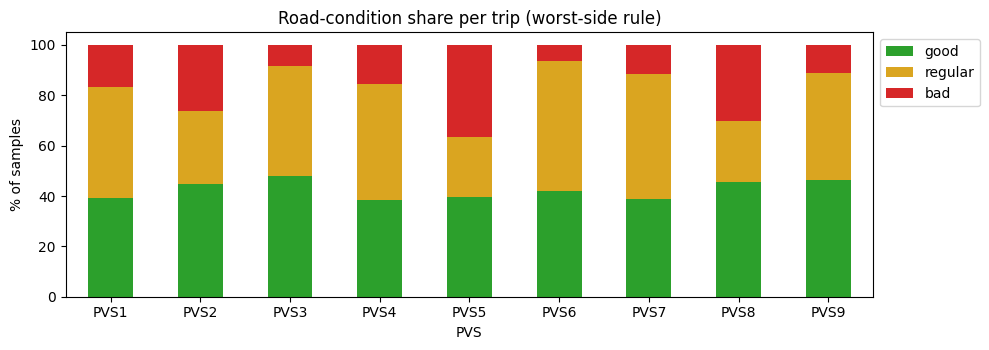

All nine synchronized files are reproduced exactly by this notebook.


In [10]:
display(result.drop(columns='note'))
share = result.set_index('PVS')[CLASSES].div(result.set_index('PVS')[CLASSES].sum(axis=1), axis=0) * 100
ax = share.plot(kind='bar', stacked=True, figsize=(10, 3.6), rot=0, color=['tab:green', 'goldenrod', 'tab:red'])
ax.set_ylabel('% of samples'); ax.set_title('Road-condition share per trip (worst-side rule)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

if not OVERWRITE:
    assert (result.status == 'identical to existing file').all(), 'at least one rebuilt trip differs from its existing file'
    print('All nine synchronized files are reproduced exactly by this notebook.')

## 9. Summary
* Each trip has three raw files: left IMUs + GPS, right IMUs + GPS, and labels. All three have the same number of rows.
* The IMU streams are sampled at 100 Hz; GPS is updated at about 1 Hz and repeated on every IMU row.
* The left and right streams have identical timestamps and identical GPS columns, so they are joined row by row without interpolation, and GPS is kept once.
* The target `road_condition` is the worse of the left and right labels. The two sides agree on most samples; disagreements are almost all between regular and bad.
* The synchronized files (60 columns, no missing values) are the input of Notebook 02. Speed-bump and surface labels are not stored in them; Notebook 03 reads those directly from the raw label files.